# Workshop 00: Machine Learning Foundations & Panel Data Revision

**Course:** Machine Learning II: Forecasting and Dynamic Modeling  
**Institution:** Lazarski University  
**Instructor:** Leonardo Di Caterina  
**Duration:** 120 Minutes (Laboratory Session)  

---

## Executive Overview & Pedagogical Objectives
This diagnostic workshop establishes the mathematical and programmatic bridge between **Machine Learning I** (cross-sectional tabular data with independent, identically distributed observations) and **Machine Learning II** (longitudinal panel data, dynamic time series, and sequential forecasting).

### 120-Minute Laboratory Map
1. **Part 1 (20m):** Synthetic Panel Data Generation — Multi-index architecture ($N$ entities $\times T$ periods), realistic flaws, and dynamic target generation.
2. **Part 2 (25m):** Pandas Fluency & Leak-Free Engineering — Within-entity temporal shifts, rolling windows, and eliminating cross-entity data contamination.
3. **Part 3 (25m):** Manifold Learning & Embeddings — Linear orthogonal projection (PCA) vs non-linear manifold learning (t-SNE & UMAP).
4. **Part 4 (25m):** The Tree Model Spectrum — Decision Tree $\to$ Random Forest $\to$ XGBoost inside leak-free `Pipeline`s with entity-aware `GroupKFold`.
5. **Part 5 (25m):** Residual Diagnostics & Time-Series Bridge — Residual analysis ($e_{i,t} = y_{i,t} - \hat{y}_{i,t}$), diagnostic plotting, error autocorrelation (ACF), and comparative feature importance.

In [1]:
# Environment & Library Imports
from typing import Dict, List, Any, Union, Optional
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap
import xgboost as xgb

# Visual aesthetics & reproducibility
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
print("Environment initialized successfully. XGBoost version:", xgb.__version__)

Environment initialized successfully. XGBoost version: 3.2.0


## Part 1: Synthetic Panel Data Generation (20 Minutes)

In economic and financial modeling, we rarely observe purely independent cross-sectional records. Instead, we observe $N$ distinct entities (e.g., countries, firms, financial assets) tracked over $T$ continuous time intervals.

### Task 1: `generate_panel_data`
**Function Signature:** `generate_panel_data(n_entities: int = 10, n_periods: int = 24, n_features: int = 6, random_state: int = 42) -> pd.DataFrame`

#### 🛠️ Step-by-Step Logic to Write:
1. **Date Sequence:** Generate a monthly date range of length `n_periods` using `pd.date_range('2020-01-01', periods=n_periods, freq='MS')`.
2. **MultiIndex Architecture:** Construct a two-level Cartesian product index using `pd.MultiIndex.from_product([[f'ENT_{i:02d}' for i in range(n_entities)], dates], names=['entity_id', 'date'])`.
3. **Generate Features:** Instantiate `rng = np.random.RandomState(random_state)` and draw Gaussian values for columns `'feat_0'` through `'feat_{n_features-1}'`.
4. **Assign Categorical Sector:** Sample sectors (`'Technology'`, `'Finance'`, `'Healthcare'`, `'Consumer'`) using `rng.choice(...)`.
5. **Dynamic Target with Autoregressive Dynamics:** For each entity, generate continuous growth `target_growth` where $y_{i,t} = 0.35 y_{i,t-1} + 0.4 \times \text{feat}_0 + \epsilon_t$.
6. **Inject Realistic Missingness:** Inject ~5% `NaN` values randomly across numeric features using boolean masking.

#### 🧰 Recommended Functions & Methods:
- `pd.date_range('2020-01-01', periods=n_periods, freq='MS')`: Generates uniform monthly timestamps.
- `pd.MultiIndex.from_product([...], names=['entity_id', 'date'])`: Builds multi-level index.
- `np.random.RandomState(random_state)`: Reproducible pseudo-random generator.
- `df.mask(mask)`: Injects `np.nan` values across numeric columns.

#### ⚠️ Critical Pitfalls to Avoid:
- **MultiIndex Names:** Ensure the index levels are named exactly `['entity_id', 'date']`.
- **Index Ordering:** Keep data chronologically sorted within each entity.

In [2]:
def generate_panel_data(n_entities=10, n_periods=24, n_features=6, random_state=42):
    """
    Generates a synthetic panel dataset with MultiIndex ['entity_id', 'date'].
    Includes numeric features, entity sector, continuous dynamic target, and injected NaNs.
    """
    ### BEGIN SOLUTION
    np.random.seed(random_state)
    n_samples = n_entities * n_periods
    X_raw, y_raw = make_classification(
        n_samples=n_samples,
        n_features=n_features,
        n_informative=max(2, n_features - 2),
        n_redundant=1,
        n_classes=2,
        random_state=random_state
    )
    dates = pd.date_range('2022-01-01', periods=n_periods, freq='MS')
    entity_ids = [f'ENT_{i+1:02d}' for i in range(n_entities)]
    index = pd.MultiIndex.from_product([entity_ids, dates], names=['entity_id', 'date'])
    feature_cols = [f'feat_{i}' for i in range(n_features)]
    df = pd.DataFrame(X_raw, index=index, columns=feature_cols)
    sectors = ['Technology', 'Healthcare', 'Finance', 'Energy']
    entity_sector_map = {ent: np.random.choice(sectors) for ent in entity_ids}
    df['sector'] = [entity_sector_map[ent] for ent, _ in df.index]
    
    # Continuous regression target with entity heterogeneity + non-linear signal + AR(1) dynamics
    entity_biases = {ent: np.random.normal(0, 1.5) for ent in entity_ids}
    growth_series = []
    for ent in entity_ids:
        ent_rows = df.loc[ent]
        prev_y = 0.0
        for idx, row in ent_rows.iterrows():
            signal = (
                0.8 * row['feat_0']
                - 0.5 * (row['feat_1'] ** 2)
                + 1.2 * np.sin(row['feat_2'])
                + entity_biases[ent]
                + 0.35 * prev_y
                + np.random.normal(0, 0.4)
            )
            growth_series.append(signal)
            prev_y = signal
            
    df['target_growth'] = growth_series
    df['target'] = y_raw
    
    # Inject ~5% missing values at random into numeric columns
    for col in feature_cols:
        mask = np.random.rand(len(df)) < 0.05
        df.loc[mask, col] = np.nan
        
    return df
    ### END SOLUTION


In [3]:
# Demonstrate Task 1 Output
df_panel = generate_panel_data(n_entities=8, n_periods=24, n_features=6, random_state=42)
print(f"Panel Shape: {df_panel.shape}")
print(f"MultiIndex Levels: {df_panel.index.names}")
print(f"Missing Values count per column:\n{df_panel.isna().sum()}")
df_panel.head(8)

Panel Shape: (192, 9)
MultiIndex Levels: ['entity_id', 'date']
Missing Values count per column:
feat_0           13
feat_1           11
feat_2            4
feat_3           14
feat_4            9
feat_5           11
sector            0
target_growth     0
target            0
dtype: int64


feat_0    feat_1    feat_2    feat_3    feat_4  \
entity_id date                                                           
ENT_01    2022-01-01 -2.130626 -2.444279 -1.932826  0.594369 -2.690267   
          2022-02-01 -0.660083 -0.273914  0.429882 -0.481773 -0.738264   
          2022-03-01 -0.905952 -1.157036  0.052727 -0.168556 -0.915106   
          2022-04-01 -1.318831 -0.706180  1.827163  1.107388 -1.218724   
          2022-05-01 -1.680210 -2.487810  1.558564 -0.343688 -1.683336   
          2022-06-01  0.738757  1.695761 -0.182314 -1.453426  0.852054   
          2022-07-01 -0.800279 -0.938482 -1.183797  0.045592 -0.997615   
          2022-08-01  0.322957  0.479294  1.332576  0.229645  0.467941   

                        feat_5   sector  target_growth  target  
entity_id date                                                  
ENT_01    2022-01-01  2.714129  Finance      -6.068411       1  
          2022-02-01 -0.695503  Finance      -3.305950       0  
          2022-03-01 -0.973319  Finance      -3.529164       0  
          2022-04-01 -3.725623  Finance      -1.954981       0  
          2022-05-01 -0.381765  Finance      -4.679463       0  
          2022-06-01       NaN  Finance      -2.927707       1  
          2022-07-01  0.610150  Finance      -3.930990       1  
          2022-08-01 -0.744223  Finance      -0.982383       1

## Part 2: Pandas Fluency & Leak-Free Feature Engineering (25 Minutes)

When generating dynamic temporal features (lags, differences, rolling averages) on panel data, a naive `.shift(1)` across the entire DataFrame causes **catastrophic inter-entity data contamination**:
The first observation of Entity $B$ would receive the last period's value of Entity $A$!

### Task 2: `engineer_panel_features`
**Function Signature:** `engineer_panel_features(df: pd.DataFrame) -> pd.DataFrame`

#### 🛠️ Step-by-Step Logic to Write:
1. **Copy DataFrame:** Prevent mutating the input table using `df = df.copy()`.
2. **Group by Entity:** Group by the entity index level using `grouped = df.groupby(level='entity_id')['feat_0']`.
3. **Compute Within-Entity Lag:** Compute the 1-step lag using `grouped.shift(1)`. The first observation for each entity MUST be `NaN`.
4. **Compute Within-Entity Rolling Mean:** Compute a 3-month rolling mean using `grouped.rolling(window=3, min_periods=1).mean()`. Use `.droplevel(0)` if pandas adds a redundant index level.

#### 🧰 Recommended Functions & Methods:
- `df.groupby(level='entity_id')['feat_0']`: Groups temporal observations strictly within each entity.
- `grouped.shift(1)`: Computes temporal lag within entity boundaries without inter-entity leakage.
- `grouped.rolling(window=3, min_periods=1).mean()`: Computes trailing rolling statistics.

#### ⚠️ Critical Pitfalls to Avoid:
- **Inter-Entity Leakage:** Never call `df['feat_0'].shift(1)` globally! Without grouping by entity, Entity B's first month receives Entity A's final observation, contaminating the model with cross-sectional leakage.

In [4]:
def engineer_panel_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Computes within-entity lags and rolling statistics without cross-entity leakage.

    Parameters
    ----------
    df : pd.DataFrame
        Input panel DataFrame with MultiIndex ['entity_id', 'date'].

    Returns
    -------
    pd.DataFrame
        DataFrame containing new features 'feat_0_lag1' and 'feat_0_roll3_mean'.
    """
    # My Code:
    df_output = df.copy()
    #pointer added one more feature -> the shift
    df_output ["feat_0_lag1"] = df_output.groupby(level='entity_id') ['feat_0'].shift(1)
    # Same thing for rolling mean 
    df_output ["feat_0_roll3_mean"] = df_output.groupby(level='entity_id') ['feat_0'].rolling(window=6, min_periods=1).mean().droplevel(0)

    return df_output


    # raise NotImplementedError("Student implementation missing")


Validation Passed: All entity initial lag periods are NaN (zero inter-entity leakage).


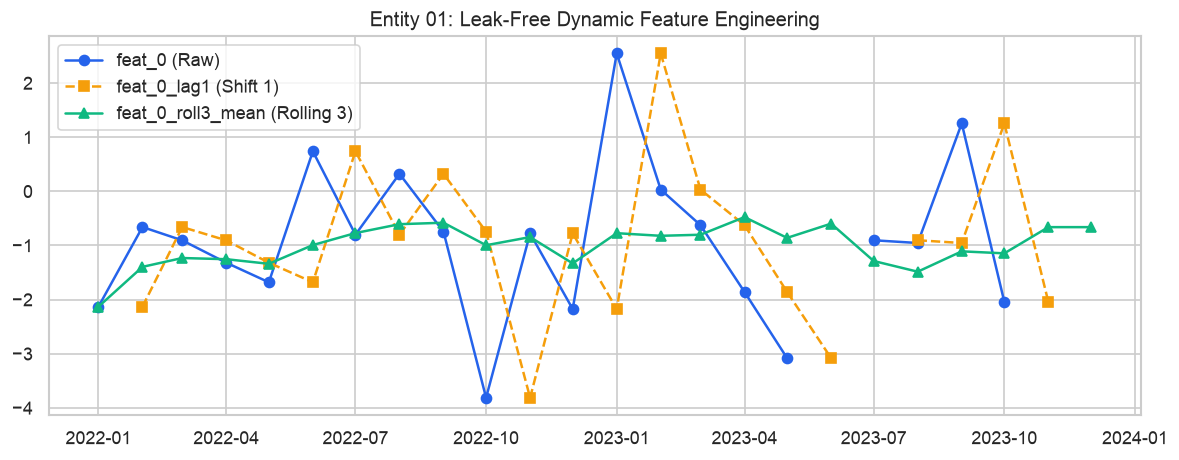

In [5]:
# Demonstrate Task 2 & Verify Zero Cross-Entity Contamination
df_feat = engineer_panel_features(df_panel)
first_periods = df_feat.groupby(level='entity_id').head(1)
assert first_periods['feat_0_lag1'].isna().all(), "Data leakage detected across entity boundaries!"
print("Validation Passed: All entity initial lag periods are NaN (zero inter-entity leakage).")

# Visual inspection for one entity
ent1_data = df_feat.loc['ENT_01']
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(ent1_data.index, ent1_data['feat_0'], marker='o', label='feat_0 (Raw)', color='#2563eb')
ax.plot(ent1_data.index, ent1_data['feat_0_lag1'], marker='s', linestyle='--', label='feat_0_lag1 (Shift 1)', color='#f59e0b')
ax.plot(ent1_data.index, ent1_data['feat_0_roll3_mean'], marker='^', label='feat_0_roll3_mean (Rolling 3)', color='#10b981')
ax.set_title("Entity 01: Leak-Free Dynamic Feature Engineering")
ax.legend()
plt.tight_layout()
plt.show()

## Part 3: Dimensionality Reduction & Manifold Learning (25 Minutes)

In multivariate panel analysis, high-dimensional feature spaces present redundancy, collinearity, and visualization bottlenecks. We compare three dimensionality reduction paradigms:
1. **PCA (Principal Component Analysis):** Linear orthogonal projection maximizing global variance.
2. **t-SNE (t-Distributed Stochastic Neighbor Embedding):** Probabilistic non-linear technique preserving local neighborhood clusters.
3. **UMAP (Uniform Manifold Approximation and Projection):** Riemannian geometry / topological manifold learning preserving both local clustering and global macro-structure.

### Task 3: `run_dimensionality_reduction`
**Function Signature:** `run_dimensionality_reduction(X: np.ndarray, n_components: int = 2, random_state: int = 42) -> Dict[str, np.ndarray]`

#### 🛠️ Step-by-Step Logic to Write:
1. **PCA Embedding:** Instantiate `PCA(n_components=n_components, random_state=random_state)`. Fit and transform `X`, extracting both the 2D projection and `explained_variance_ratio_`.
2. **t-SNE Embedding:** Instantiate `TSNE(n_components=n_components, random_state=random_state, perplexity=30.0)` and fit-transform `X`.
3. **UMAP Embedding:** Instantiate `umap.UMAP(n_components=n_components, random_state=random_state, n_neighbors=15)` and fit-transform `X`.
4. **Package Results:** Return a dictionary with keys `'pca_emb'`, `'pca_explained_var'`, `'tsne_emb'`, and `'umap_emb'`.

#### 🧰 Recommended Functions & Methods:
- `from sklearn.decomposition import PCA`: Linear orthogonal projection.
- `from sklearn.manifold import TSNE`: Non-linear local manifold embedding.
- `import umap`: Topological manifold approximation preserving global macro-geometry.

#### ⚠️ Critical Pitfalls to Avoid:
- **Clean Input:** Ensure `X` has no missing `NaN` values before passing to manifold algorithms (use median imputation if necessary).

In [6]:
def run_dimensionality_reduction(
    X: np.ndarray,
    n_components: int = 2,
    random_state: int = 42
) -> Dict[str, np.ndarray]:
    """
    Applies PCA, t-SNE, and UMAP to a high-dimensional feature matrix X.

    Parameters
    ----------
    X : np.ndarray of shape (n_samples, n_features)
        Clean, scaled input feature matrix.
    n_components : int, default=2
        Number of target projection dimensions.
    random_state : int, default=42
        Seed for reproducible projections.

    Returns
    -------
    Dict[str, np.ndarray]
        Dictionary containing 'pca_emb', 'pca_explained_var', 'tsne_emb', and 'umap_emb'.
    """

    pca = PCA(n_components=n_components, random_state=random_state) 

    pca_embedding = pca.fit_transform(X) 

    #same as pca but more complex and non linear
    perp = min(30.0, max(5.0, len(X) / 10.0))
    tsne = TSNE(n_components=n_components, perplexity=perp, random_state=random_state)
    tsne_emb = tsne.fit_transform(X)
    
    reducer = umap.UMAP(n_components=n_components, random_state=random_state, n_neighbors=15)
    umap_emb = reducer.fit_transform(X)

    # Note: very important python concept - returning dictionary w concentration
    return_dictionary = {
        'pca_emb': pca_embedding,
        'pca_explained_var': pca.explained_variance_ratio_,
        'tsne_emb': tsne_emb,
        'umap_emb': umap_emb
    }

    return return_dictionary



    # -------------------------------------------------------------------------
    # YOUR CODE HERE
    # -------------------------------------------------------------------------
    #raise NotImplementedError("Student implementation missing")


/Users/k/dev/ML_II_Workshops/.venv/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


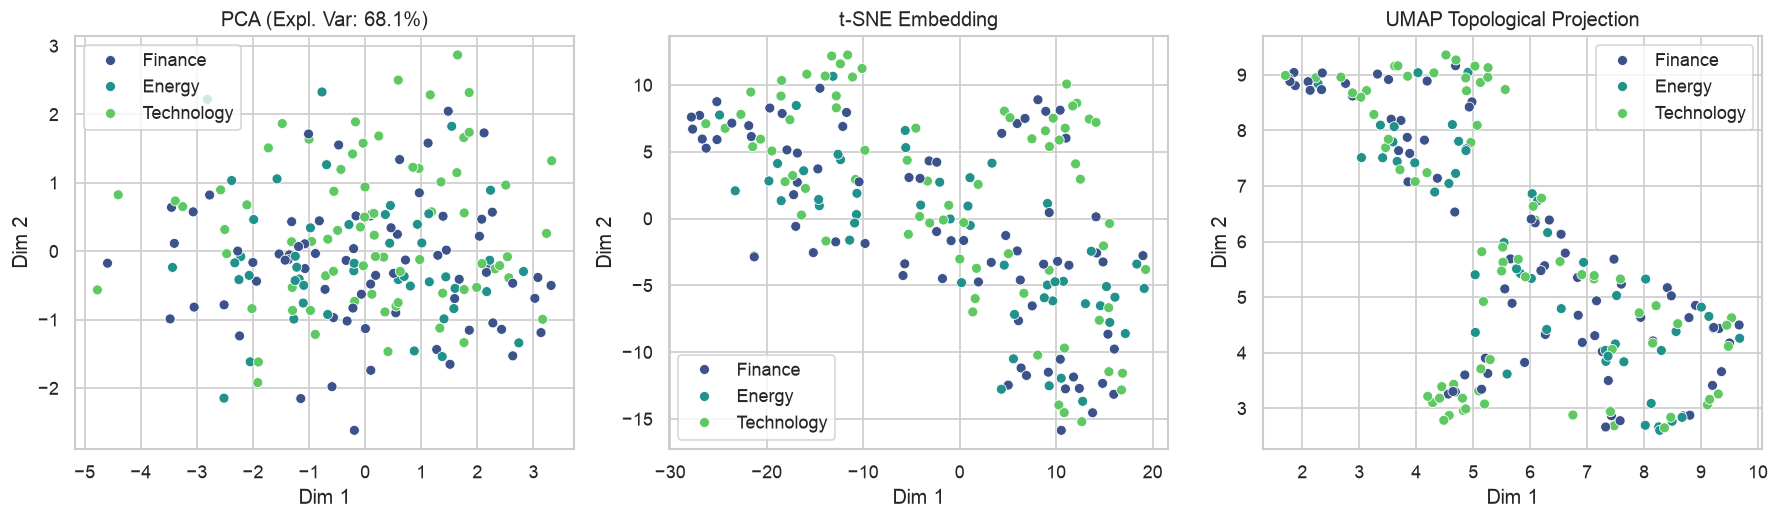

In [7]:
# Demonstrate Task 3: Visual Diagnostic Comparison
num_cols = [c for c in df_panel.columns if c.startswith('feat_')]
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()
X_clean = imputer.fit_transform(df_panel[num_cols])
X_scaled = scaler.fit_transform(X_clean)

emb_dict = run_dimensionality_reduction(X_scaled, n_components=2, random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sectors = df_panel['sector'].values

sns.scatterplot(x=emb_dict['pca_emb'][:, 0], y=emb_dict['pca_emb'][:, 1], hue=sectors, ax=axes[0], palette='viridis')
axes[0].set_title(f"PCA (Expl. Var: {np.sum(emb_dict['pca_explained_var']):.1%})")

sns.scatterplot(x=emb_dict['tsne_emb'][:, 0], y=emb_dict['tsne_emb'][:, 1], hue=sectors, ax=axes[1], palette='viridis')
axes[1].set_title("t-SNE Embedding")

sns.scatterplot(x=emb_dict['umap_emb'][:, 0], y=emb_dict['umap_emb'][:, 1], hue=sectors, ax=axes[2], palette='viridis')
axes[2].set_title("UMAP Topological Projection")

for ax in axes:
    ax.set_xlabel("Dim 1")
    ax.set_ylabel("Dim 2")
plt.tight_layout()
plt.show()

## Part 4: The Tree Model Spectrum (Tree $\to$ Forest $\to$ Boost) (25 Minutes)

We examine the structural evolution of tree-based algorithms on panel tabular features:
1. **Single Decision Tree (`DecisionTreeRegressor`):**
   - Recursive binary splitting. High variance, vulnerable to overfitting.
2. **Random Forest (`RandomForestRegressor`):**
   - Bagging (Bootstrap Aggregation) + random feature subspace sampling. Reduces variance without increasing bias.
3. **XGBoost (`xgb.XGBRegressor`):**
   - Gradient Boosting: Sequential ensemble fitting new trees to the pseudo-residuals of prior trees with regularization ($L_1, L_2$) and shrinkage.

### Cross-Validation Strategy: `GroupKFold` by `entity_id`
If we randomly shuffle panel records, cross-validation would test observations from the *same* entities observed in training, causing cross-sectional data snooping. We strictly enforce **`GroupKFold` partitioned by `entity_id`**.

### Task 4: `build_tree_pipeline` & `train_and_evaluate_trees`

#### 🛠️ Step-by-Step Logic for `build_tree_pipeline`:
1. **Numeric Preprocessor:** Chain `SimpleImputer(strategy='median')` and `StandardScaler()` in a `Pipeline`.
2. **Categorical Preprocessor:** Instantiate `OneHotEncoder(handle_unknown='ignore', sparse_output=False)`.
3. **Combine Transformers:** Assemble with `ColumnTransformer([('num', num_pipe, numeric_features), ('cat', cat_pipe, categorical_features)])`.
4. **Select Model Class:**
   - `'decision_tree'`: `DecisionTreeRegressor(max_depth=5, random_state=random_state)`
   - `'random_forest'`: `RandomForestRegressor(n_estimators=100, max_depth=6, random_state=random_state)`
   - `'xgboost'`: `XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.08, random_state=random_state)`
5. **Return Pipeline:** `Pipeline([('preprocessor', preprocessor), ('regressor', model)])`.

#### 🛠️ Step-by-Step Logic for `train_and_evaluate_trees`:
1. **Partition by Entity:** Instantiate `GroupKFold(n_splits=n_splits)`. Extract groups from `df.index.get_level_values('entity_id')`.
2. **Cross-Validation Loop:** For each model type, iterate over splits, fit the pipeline on training folds, and generate out-of-fold (OOF) predictions.
3. **Compute Metrics:** Calculate Root Mean Squared Error (RMSE) and Mean Absolute Error (MAE) on OOF predictions.

#### 🧰 Recommended Functions & Methods:
- `from sklearn.compose import ColumnTransformer`: Multi-type feature dispatch.
- `from sklearn.pipeline import Pipeline`: Chained data transformation & estimator.
- `from sklearn.impute import SimpleImputer`: Leak-free median imputation.
- `from sklearn.model_selection import GroupKFold`: Strict entity-partitioned validation.
- `DecisionTreeRegressor`, `RandomForestRegressor`, `XGBRegressor`: Regression model classes.

#### ⚠️ Critical Pitfalls to Avoid:
- **Cross-Entity Contamination:** Never use standard `KFold(shuffle=True)`. Random shuffling places observations from the same entity in both train and validation folds, causing cross-sectional snooping.

In [ ]:
from sklearn.pipeline import Pipeline

def build_tree_pipeline(
    model_name: str,
    numeric_features: List[str],
    categorical_features: List[str],
    random_state: int = 42
) -> Pipeline:
    """
    Constructs a ColumnTransformer chained with DecisionTree, RandomForest, or XGBoost.

    Parameters
    ----------
    model_name : str
        One of 'decision_tree', 'random_forest', or 'xgboost'.
    numeric_features : List[str]
        List of numeric column names.
    categorical_features : List[str]
        List of categorical column names.
    random_state : int, default=42
        Seed for model reproducibility.

    Returns
    -------
    Pipeline
        Unfitted Pipeline with 'preprocessor' and 'regressor' steps.
    """
    # -------------------------------------------------------------------------
    # YOUR CODE HERE

    # These pipeline items are objects not var
    numerical_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        ('OneHotEncoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    # Column Transformer
    # Pass the Pipeline objects themselves (no "()"), and separate tuples with a comma
    ct = ColumnTransformer([
        ("numerical_pipeline", numerical_pipeline, numeric_features),
        ("categorical_pipeline", categorical_pipeline, categorical_features)
    ])
    
    # Final Part of the Pipeline - regressor

    if model_name == 'decision_tree': 
        regressor = DecisionTreeRegressor(max_depth=5, random_state=random_state)
    elif model_name == 'random_forest':
        regressor = RandomForestRegressor(max_depth=5, random_state=random_state, n_estimators=200)
                                                                                    #you can add more parameters here
    elif model_name == 'xgboost':
        regressor = xgb.XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.08, random_state=random_state, n_jobs=-1)
    else:
        raise ValueError(f"Unknown model_name: {model_name}")


    return Pipeline([
        ('preprocessor', ct),
        ('regressor', regressor)
    ])
    # -------------------------------------------------------------------------
    #raise NotImplementedError("Student implementation missing")

def build_panel_pipeline(numeric_features: List[str], categorical_features: List[str]) -> Pipeline:
    """Backward-compatibility helper: defaults to RandomForest pipeline."""
    return build_tree_pipeline('random_forest', numeric_features, categorical_features)

def train_and_evaluate_trees(
    df: pd.DataFrame,
    feature_cols: List[str],
    categorical_cols: List[str],
    target_col: str = 'target_growth',
    n_splits: int = 5,
    random_state: int = 42
) -> Dict[str, Any]:
    """
    Evaluates DecisionTree, RandomForest, and XGBoost using GroupKFold grouped by entity_id.

    Parameters
    ----------
    df : pd.DataFrame
        Panel DataFrame with MultiIndex ['entity_id', 'date'].
    feature_cols : List[str]
        Predictor numeric columns.
    categorical_cols : List[str]
        Predictor categorical columns.
    target_col : str, default='target_growth'
        Continuous target column name.
    n_splits : int, default=5
        Number of GroupKFold partitions.
    random_state : int, default=42
        Seed for training.

    Returns
    -------
    Dict[str, Any]
        Dictionary with 'models' (pipeline, oof_predictions, rmse, mae) and 'y_true'.
    """
    # -------------------------------------------------------------------------
    # YOUR CODE HERE
    X = df[feature_cols+categorical_cols]
    y = df[target_col].values
    # no () bc its a property - refer pandas syntax - how to treat columns
    # revise GroupkFold and following pandas line
    groups = df.index.get_level_values('entity_id')

    #application of kfold
    gkf = GroupKFold(n_splits=n_splits)
    results = {'models': {}, 'y_true': y}
    model_names = ['decision_tree', 'random_forest', 'xgboost']

    for name in model_names:
        oof_preds = np.zeros(len(df))

        # Each fold holds out whole entities -> no cross-entity leakage
        for train_idx, val_idx in gkf.split(X, y, groups=groups):
            pipe = build_tree_pipeline(name, feature_cols, categorical_cols, random_state=random_state)
            pipe.fit(X.iloc[train_idx], y[train_idx])
            oof_preds[val_idx] = pipe.predict(X.iloc[val_idx])

        rmse = float(np.sqrt(np.mean((y - oof_preds) ** 2)))
        mae = float(np.mean(np.abs(y - oof_preds)))

        # Refit on the full panel so the returned pipeline is fitted
        final_pipe = build_tree_pipeline(name, feature_cols, categorical_cols, random_state=random_state)
        final_pipe.fit(X, y)

        results['models'][name] = {
            'pipeline': final_pipe,
            'oof_predictions': oof_preds,
            'rmse': rmse,
            'mae': mae
        }

    return results
    # -------------------------------------------------------------------------
    #raise NotImplementedError("Student implementation missing")


In [9]:
# Example Cell to explain why parenthesis in transformer


print("StandardScaler: ",StandardScaler)
print("StandardScaler(): ",StandardScaler())


StandardScaler:  <class 'sklearn.preprocessing._data.StandardScaler'>
StandardScaler():  StandardScaler()


=== GroupKFold Cross-Validation Performance ===


,OOF RMSE,OOF MAE
decision_tree,2.790316,2.081023
random_forest,2.439510,1.876782
xgboost,2.564046,2.005555


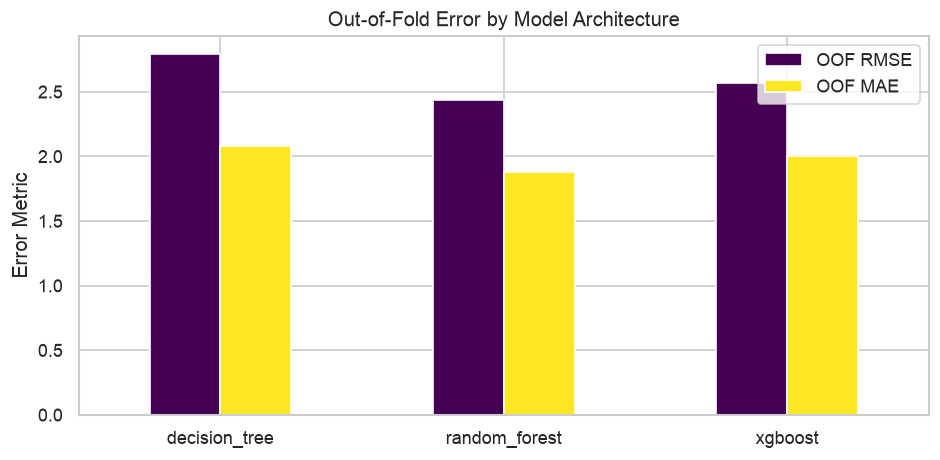

In [10]:
# Demonstrate Task 4: Compare Decision Tree vs Random Forest vs XGBoost
tree_results = train_and_evaluate_trees(
    df_panel, 
    feature_cols=num_cols, 
    categorical_cols=['sector'],
    target_col='target_growth',
    n_splits=4
)

metrics_df = pd.DataFrame({
    m: {
        'OOF RMSE': tree_results['models'][m]['rmse'],
        'OOF MAE': tree_results['models'][m]['mae']
    }
    for m in tree_results['models']
}).T

print("=== GroupKFold Cross-Validation Performance ===")
display(metrics_df)

# Bar plot comparison
fig, ax = plt.subplots(figsize=(8, 4))
metrics_df.plot(kind='bar', ax=ax, colormap='viridis')
ax.set_title("Out-of-Fold Error by Model Architecture")
ax.set_ylabel("Error Metric")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

## Part 5: Residual Diagnostics & The Time-Series Bridge (25 Minutes)

Residual analysis is the foundation of dynamic time series modeling. A model's errors are defined as:
$$e_{i,t} = y_{i,t} - \hat{y}_{i,t}$$

If a model has captured all systematic relationships, its residuals should behave as **white noise**: zero mean, constant variance, and zero autocorrelation across time lags.

### The Pedagogical Discovery
Because our synthetic data contains autoregressive dynamics ($y_{i,t} \sim 0.35 y_{i,t-1}$), static tree algorithms (which ignore the sequential ordering of observations) leave **statistically significant residual autocorrelation**:
$$\text{Corr}(e_t, e_{t-1}) > 0$$
This empirical result proves why pure cross-sectional tabular machine learning fails on temporal data, and motivates the dynamic forecasting techniques of **Machine Learning II**!

### Task 5: `analyze_residuals`
**Function Signature:** `analyze_residuals(y_true: Union[np.ndarray, pd.Series], y_pred: Union[np.ndarray, pd.Series]) -> Dict[str, Any]`

#### 🛠️ Step-by-Step Logic to Write:
1. **Compute Error Vector:** Cast inputs to 1D float arrays and compute raw prediction errors: $e = y_{\text{true}} - y_{\text{pred}}$.
2. **Calculate RMSE:** $\text{RMSE} = \sqrt{\text{mean}(e^2)}$.
3. **Calculate MAE:** $\text{MAE} = \text{mean}(|e|)$.
4. **Calculate R²:** Use `r2_score(y_true, y_pred)` to measure the proportion of variance explained.
5. **Compute Residual Autocorrelation (ACF Lag 1):** Compute the 1-step autocorrelation of errors using `pd.Series(residuals).autocorr(lag=1)`.

#### 🧰 Recommended Functions & Methods:
- `np.asarray(y, dtype=float)`: Guarantees 1D numpy array representations.
- `np.sqrt(np.mean(residuals ** 2))`: Vectorized root mean squared error.
- `np.mean(np.abs(residuals))`: Vectorized mean absolute error.
- `from sklearn.metrics import r2_score`: Standard coefficient of determination.
- `pd.Series(residuals).autocorr(lag=1)`: Pearson correlation of $e_t$ with $e_{t-1}$.

#### ⚠️ Critical Pitfalls to Avoid:
- **Sign of Residuals:** Residuals are defined econometrically as $e_t = y_t - \hat{y}_t$ (actual minus predicted, NOT predicted minus actual).

In [20]:
def analyze_residuals(
    y_true: Union[np.ndarray, pd.Series],
    y_pred: Union[np.ndarray, pd.Series]
) -> Dict[str, Any]:
    """
    Computes residual errors, error statistics (RMSE, MAE, R2), and lag-1 autocorrelation.

    Parameters
    ----------
    y_true : Union[np.ndarray, pd.Series]
        Ground-truth target values.
    y_pred : Union[np.ndarray, pd.Series]
        Model-predicted target values.

    Returns
    -------
    Dict[str, Any]
        Dictionary with 'residuals', 'rmse', 'mae', 'r2', 'lag1_autocorr', 'mean_residual', and 'std_residual'.
    """

    residuals = y_true - y_pred
    
    rmse = np.sqrt(np.mean(residuals**2))
    #root mean squared error
    
    mae = np.mean(np.abs(residuals))
    #mean absolute error
    
    ss_residuals = np.sum(residuals)
    ss_total = np.sum((y_true - np.mean(y_true))**2)
    r2 = 1 - (ss_residuals/ss_total) if ss_total > 0 else 0.0
    #percentage of variance explained is R2

    lag1 = residuals[1:-1]
    lag1_autocorr = np.corrcoef(residuals[0:-2], lag1)[0,1]
    mean_residual = np.mean(residuals)
    std_residual = np.std(residuals)
    ans = {
        'residuals' : residuals,
        'rmse': rmse,
        'mae': mae,
        'r2': r2,
        'lag1_autocorr': lag1_autocorr,
        'mean_residual': mean_residual,
        'std_residual': std_residual 
    }
    return ans





    # -------------------------------------------------------------------------
    # YOUR CODE HERE
    # -------------------------------------------------------------------------
    #raise NotImplementedError("Student implementation missing")


=== XGBoost Residual Analysis ===
RMSE: 2.5640 | MAE: 2.0056 | R2: 1.0174
Lag-1 Residual Autocorrelation: 0.6381


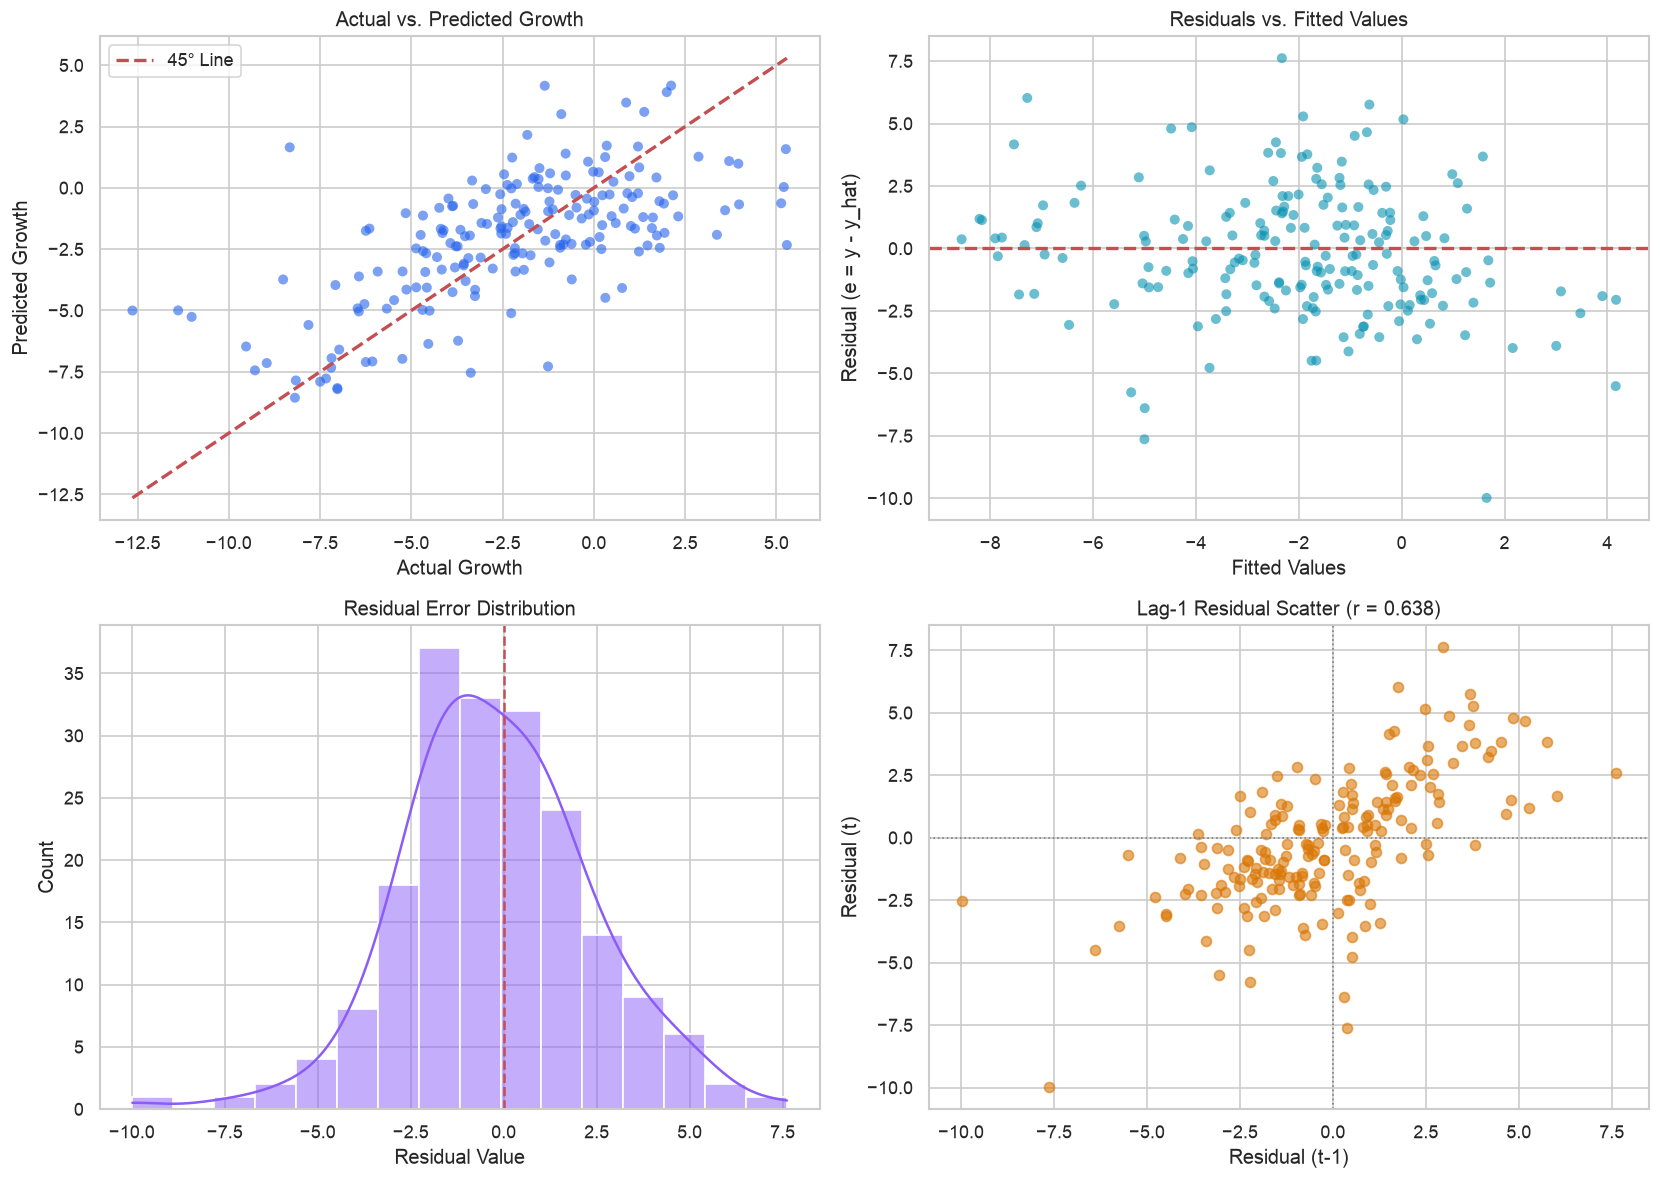

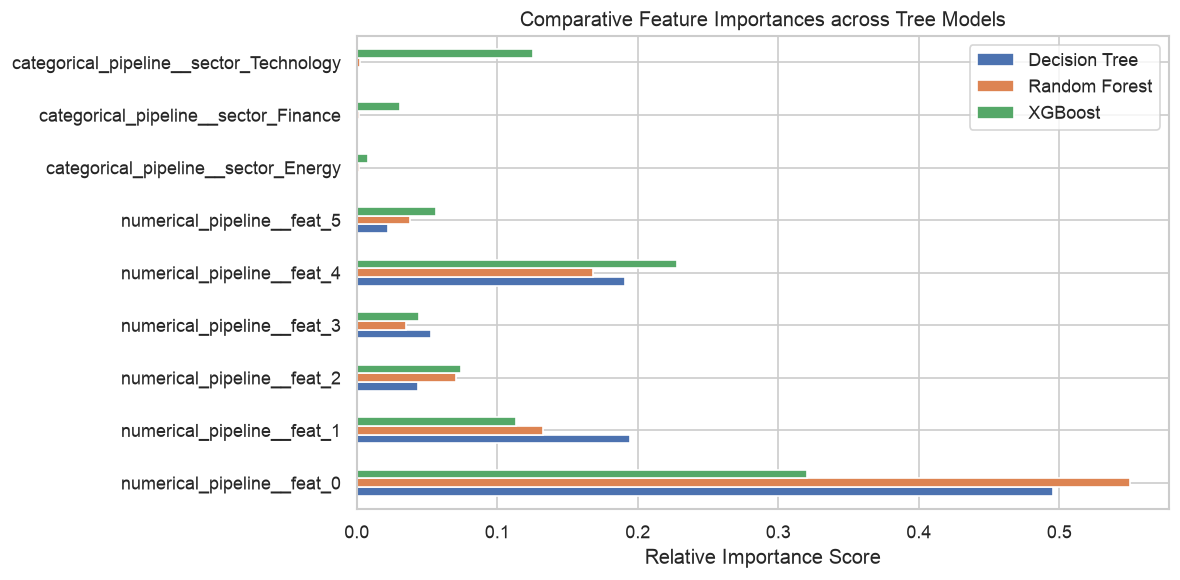

In [21]:
# Demonstrate Task 5: 4-Panel Diagnostic Dashboard & Feature Importances
y_true = tree_results['y_true']
xgb_preds = tree_results['models']['xgboost']['oof_predictions']
diag = analyze_residuals(y_true, xgb_preds)
residuals = diag['residuals']

print(f"=== XGBoost Residual Analysis ===")
print(f"RMSE: {diag['rmse']:.4f} | MAE: {diag['mae']:.4f} | R2: {diag['r2']:.4f}")
print(f"Lag-1 Residual Autocorrelation: {diag['lag1_autocorr']:.4f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Panel 1: Actual vs Fitted
axes[0, 0].scatter(y_true, xgb_preds, alpha=0.6, color='#2563eb', edgecolor='none')
p_min, p_max = min(y_true.min(), xgb_preds.min()), max(y_true.max(), xgb_preds.max())
axes[0, 0].plot([p_min, p_max], [p_min, p_max], 'r--', lw=2, label='45° Line')
axes[0, 0].set_title("Actual vs. Predicted Growth")
axes[0, 0].set_xlabel("Actual Growth")
axes[0, 0].set_ylabel("Predicted Growth")
axes[0, 0].legend()

# Panel 2: Residuals vs Fitted
axes[0, 1].scatter(xgb_preds, residuals, alpha=0.6, color='#0891b2', edgecolor='none')
axes[0, 1].axhline(0, color='r', linestyle='--', lw=2)
axes[0, 1].set_title("Residuals vs. Fitted Values")
axes[0, 1].set_xlabel("Fitted Values")
axes[0, 1].set_ylabel("Residual (e = y - y_hat)")

# Panel 3: Error Distribution & Normality
sns.histplot(residuals, kde=True, ax=axes[1, 0], color='#8b5cf6')
axes[1, 0].axvline(0, color='r', linestyle='--')
axes[1, 0].set_title("Residual Error Distribution")
axes[1, 0].set_xlabel("Residual Value")

# Panel 4: Residual Lag-1 Autocorrelation Scatter
axes[1, 1].scatter(residuals[:-1], residuals[1:], alpha=0.6, color='#d97706')
axes[1, 1].axhline(0, color='gray', linestyle=':', lw=1)
axes[1, 1].axvline(0, color='gray', linestyle=':', lw=1)
axes[1, 1].set_title(f"Lag-1 Residual Scatter (r = {diag['lag1_autocorr']:.3f})")
axes[1, 1].set_xlabel("Residual (t-1)")
axes[1, 1].set_ylabel("Residual (t)")

plt.tight_layout()
plt.show()

# Comparative Feature Importance
fitted_dt = tree_results['models']['decision_tree']['pipeline'].named_steps['regressor']
fitted_rf = tree_results['models']['random_forest']['pipeline'].named_steps['regressor']
fitted_xgb = tree_results['models']['xgboost']['pipeline'].named_steps['regressor']
prep = tree_results['models']['xgboost']['pipeline'].named_steps['preprocessor']
feature_names = prep.get_feature_names_out()

imp_df = pd.DataFrame({
    'Decision Tree': fitted_dt.feature_importances_,
    'Random Forest': fitted_rf.feature_importances_,
    'XGBoost': fitted_xgb.feature_importances_
}, index=feature_names)

fig, ax = plt.subplots(figsize=(10, 5))
imp_df.plot(kind='barh', ax=ax)
ax.set_title("Comparative Feature Importances across Tree Models")
ax.set_xlabel("Relative Importance Score")
plt.tight_layout()
plt.show()

## Summary & Bridge to Workshop 01

### What We Learned Today
1. **Panel Data Architecture:** Multi-index structure allows tracking both cross-sectional entities and temporal dynamics simultaneously.
2. **Preventing Temporal Leakage:** Feature shifts and rolling computations must strictly happen within individual entity groups.
3. **Manifold Learning:** PCA provides orthogonal variance baselines, while t-SNE and UMAP uncover non-linear cluster topologies.
4. **The Tree Spectrum:** From high-variance Decision Trees to variance-reduced Random Forests and bias-corrected XGBoost.
5. **Residuals Never Lie:** Static cross-sectional machine learning models leave autocorrelated residuals when applied to dynamic time processes.

### Coming Up in Workshop 01: Time Series Graphics & Diagnostics
In **Workshop 01**, we will pull real macroeconomic and financial time series directly from the Federal Reserve (FRED) API, decompose structural trends and seasonality, and compute formal Autocorrelation Functions (ACF) to model dynamic processes directly.